# 03 — Backtest 001.1: cruzamento de médias + walk-forward + machine learning

**LHS Quant Lab** · notebook didático

## De onde viemos
No **Backtest 001** (notebook `02_primeiro_backtest`) testamos a regra mais simples de *trend following*
no EURUSD H4: **SMA 20 acima da SMA 50 → comprado, abaixo → vendido**. Resultado: **reprovado**
(−20% líquido, Sharpe −0,12, percentil 41 contra sinais aleatórios).

Aquele teste tinha **parâmetros fixos** e **nenhum aprendizado de máquina**. Esta versão, a **001.1**,
mantém a mesma regra base e acrescenta duas ferramentas para ver se elas salvam a estratégia:

| Ferramenta | Pergunta que responde |
|---|---|
| **Otimização walk-forward** | Se eu reescolher as médias todo ano, olhando só o passado, a estratégia melhora *fora da amostra*? |
| **Filtro de machine learning (meta-labeling)** | Um modelo consegue prever **quais cruzamentos** vão dar lucro e pular os ruins? |

> **Por que "1.1" e não "002"?** Porque a regra base é a mesma do 001. Só mudam as camadas por cima dela.

## O cuidado número 1 deste notebook: não enganar a si mesmo
Otimização e machine learning são as duas formas **mais fáceis** de fabricar um backtest bonito que quebra
na conta real (*overfitting*). Por isso, aqui, **toda** decisão é tomada só com dados que já existiam
naquele momento:
- a otimização escolhe as médias na janela de **treino** e é avaliada na janela **seguinte**, que ela nunca viu;
- o modelo de ML é **retreinado todo ano** só com operações **já encerradas** antes do ano testado;
- o resultado do ML é comparado com **filtros aleatórios** que pulam a mesma quantidade de operações.

## Roteiro
1. Configuração
2. Dados e funções do motor de backtest
3. Conferência: reproduzir o Backtest 001
4. Otimização walk-forward
5. Machine learning: o que é meta-labeling
6. Features (as "pistas" do modelo)
7. Treino walk-forward dos modelos
8. O filtro funcionou? Qualidade das previsões
9. Filtro de ML × filtros aleatórios
10. Comparação final (fora da amostra, 2014 → hoje)
11. Salvar os resultados
12. Conclusões e exercícios

## 1. Configuração
Tudo o que pode mudar fica aqui.

- **Regra base:** `MEDIA_RAPIDA` × `MEDIA_LENTA` = 20 × 50, igual ao 001.
- **Custos:** spread real de cada barra + `SLIPPAGE_PONTOS` por lado + comissão.
- **Walk-forward:** janela de treino de `ANOS_TREINO` anos, janela de teste de `ANOS_TESTE` ano, andando de ano em ano.
  O primeiro ano testado é `INICIO_OOS` (2014), porque precisamos de 4 anos de treino a partir de 2010.
- `GRADE_RAPIDAS` / `GRADE_LENTAS`: as 19 combinações candidatas (as mesmas do mapa de calor do 001).
- `MIN_TRADES_TREINO`: uma combinação só pode ser escolhida se tiver operado pelo menos isso no treino
  (evita escolher algo que "acertou" 3 operações por sorte).
- **ML:** `PROB_MINIMA` é a probabilidade de acerto que o modelo precisa prever para a operação ser aceita.
  `MIN_TRADES_ML` é o mínimo de operações encerradas para treinar o modelo.
- `SEED`: fixa toda a aleatoriedade (modelos e filtros aleatórios).

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# ---------------- parâmetros do teste ----------------
BACKTEST_ID = "001.1"
SIMBOLO = "EURUSD"
TIMEFRAME = "H4"
MEDIA_RAPIDA = 20  # regra base (igual ao 001)
MEDIA_LENTA = 50

SLIPPAGE_PONTOS = 2  # por lado (entrada e saída)
COMISSAO_PCT = 0.0  # % por operação completa; XM Standard = 0
CAPITAL_INICIAL = 10_000
DATA_INICIO = "2010-01-01"

# walk-forward
ANOS_TREINO = 4
ANOS_TESTE = 1
INICIO_OOS = "2014-01-01"  # primeiro ano fora da amostra
GRADE_RAPIDAS = [5, 10, 20, 30, 50]
GRADE_LENTAS = [50, 100, 150, 200]
MIN_TRADES_TREINO = 30

# machine learning
PROB_MINIMA = 0.50
MIN_TRADES_ML = 100
N_SIM = 300
SEED = 42

RAIZ = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "dados" / "xm").is_dir()),
    None,
)
if RAIZ is None:
    raise FileNotFoundError(f"Não encontrei a pasta dados/xm a partir de {Path.cwd()}")
PASTA_DADOS = RAIZ / "dados" / "xm"
sys.path.insert(0, str(RAIZ / "src"))
from lhsquant.estilo import aplicar_estilo, CORES

aplicar_estilo()  # paleta Terminal Âmbar
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 2. Dados e funções do motor de backtest
Mesmos dados do 001 (XM via MT5, banco Parquet). Em vez de repetir o código passo a passo, juntamos o motor
em **funções pequenas**, porque vamos rodar dezenas de backtests:

| Função | O que faz |
|---|---|
| `posicao_sma(r, l)` | sinal na barra **fechada** (+1/−1) e posição com `shift(1)`: decide em *t*, carrega em *t+1* |
| `retornos(pos)` | retorno por barra = posição × retorno do mercado − custo da operação completa na entrada |
| `lista_trades(pos, ret)` | agrupa as barras em operações (entrada, saída, direção, resultado líquido) |
| `metricas(ret, trades)` | retorno, CAGR, nº de trades, win rate, payoff, expectativa, fator de lucro, drawdown, Sharpe, Sortino |

Um detalhe importante: `retornos()` recebe **qualquer** série de posições. Assim, tanto a posição montada
pelo walk-forward quanto a posição filtrada pelo ML pagam os custos **exatamente da mesma forma**.

In [2]:
df = pd.read_parquet(PASTA_DADOS / SIMBOLO / f"{TIMEFRAME}.parquet").sort_index()
df = df.loc[DATA_INICIO:].copy()
info = pd.read_parquet(PASTA_DADOS / "info_simbolos.parquet")
PONTO = float(info.loc[info["simbolo"] == SIMBOLO, "ponto"].iloc[-1])
BARRAS_ANO = len(df) / ((df.index[-1] - df.index[0]).days / 365.25)

ret_mercado = df["fechamento"].pct_change().fillna(0)
# custo da operação completa (ida+volta) em %, cobrado com o spread da barra em que a ordem foi executada
custo_pct = ((df["spread"] + 2 * SLIPPAGE_PONTOS) * PONTO / df["fechamento"] + COMISSAO_PCT / 100).shift(1).fillna(0)

print(f"{SIMBOLO} {TIMEFRAME}: {len(df):,} barras de {df.index[0]:%Y-%m-%d} a {df.index[-1]:%Y-%m-%d}")
print(f"Duplicadas: {df.index.duplicated().sum()} | fechamentos vazios: {df['fechamento'].isna().sum()} | barras/ano: {BARRAS_ANO:,.0f}")

EURUSD H4: 26,119 barras de 2010-01-04 a 2026-10-16
Duplicadas: 0 | fechamentos vazios: 0 | barras/ano: 1,557


In [3]:
def posicao_sma(rapida, lenta, dados=df):
    mr = dados["fechamento"].rolling(rapida).mean()
    ml = dados["fechamento"].rolling(lenta).mean()
    sinal = pd.Series(np.where(mr > ml, 1, -1), index=dados.index).where(ml.notna(), 0)
    return sinal.shift(1).fillna(0)  # decide no fechamento de t, carrega em t+1


def entradas(pos):
    return (pos != pos.shift(1)) & (pos != 0)


def retornos(pos):
    return pos * ret_mercado - np.where(entradas(pos), custo_pct, 0.0)


def lista_trades(pos, ret):
    grupo = (pos != pos.shift(1)).cumsum()
    dentro = pos != 0
    t = (
        pd.DataFrame({"pos": pos[dentro], "ret": ret[dentro], "g": grupo[dentro]})
        .groupby("g")
        .agg(
            entrada=("pos", lambda s: s.index[0]),
            saida=("pos", lambda s: s.index[-1]),
            direcao=("pos", "first"),
            barras=("pos", "size"),
            resultado=("ret", lambda r: (1 + r).prod() - 1),
        )
        .reset_index(drop=True)
    )
    return t


def curva(ret, capital=CAPITAL_INICIAL):
    return capital * (1 + ret).cumprod()


def drawdown(cap):
    return cap / cap.cummax() - 1


def sharpe(ret):
    return ret.mean() / ret.std() * np.sqrt(BARRAS_ANO) if ret.std() > 0 else np.nan


def metricas(ret, trades_=None):
    if trades_ is None:
        trades_ = pd.DataFrame({"resultado": []})
    cap = (1 + ret).cumprod()
    anos = len(ret) / BARRAS_ANO
    ganhos = trades_.loc[trades_["resultado"] > 0, "resultado"]
    perdas = trades_.loc[trades_["resultado"] <= 0, "resultado"]
    neg = ret[ret < 0]
    return pd.Series(
        {
            "Retorno total %": (cap.iloc[-1] - 1) * 100,
            "CAGR %": (cap.iloc[-1] ** (1 / anos) - 1) * 100,
            "Nº trades": len(trades_) or np.nan,
            "Win rate %": len(ganhos) / len(trades_) * 100 if len(trades_) else np.nan,
            "Payoff": ganhos.mean() / abs(perdas.mean()) if len(perdas) else np.nan,
            "Expectativa %/trade": trades_["resultado"].mean() * 100,
            "Fator de lucro": ganhos.sum() / abs(perdas.sum()) if len(perdas) else np.nan,
            "Máx. drawdown %": drawdown(cap).min() * 100,
            "Sharpe": sharpe(ret),
            "Sortino": ret.mean() / np.sqrt((neg**2).sum() / len(ret)) * np.sqrt(BARRAS_ANO),
        }
    )

## 3. Conferência: reproduzir o Backtest 001
Antes de acrescentar qualquer coisa, o motor novo precisa dar **o mesmo número** do motor antigo.
Se a regra 20×50 no período completo não der ≈ −20,2% de retorno e 586 operações, há um erro no código
(ou os dados foram atualizados — aí a diferença deve ser pequena).

In [4]:
pos_base = posicao_sma(MEDIA_RAPIDA, MEDIA_LENTA)
ret_base = retornos(pos_base)
trades_base = lista_trades(pos_base, ret_base)
m001 = metricas(ret_base, trades_base)
print(f"Reprodução do 001 -> retorno {m001['Retorno total %']:.1f}% | trades {m001['Nº trades']:.0f} | Sharpe {m001['Sharpe']:.2f}")
print("Esperado (17/10/2026) -> retorno -20.2% | trades 586 | Sharpe -0.12")

Reprodução do 001 -> retorno -20.2% | trades 586 | Sharpe -0.12
Esperado (17/10/2026) -> retorno -20.2% | trades 586 | Sharpe -0.12


## 4. Otimização walk-forward
### O problema da otimização comum
No 001, o mapa de calor mostrou que a melhor combinação **in-sample** foi 20×200. Escolher a melhor célula
olhando o passado inteiro e depois dizer "essa estratégia dá X%" é **trapaça involuntária**: com 19 tentativas,
alguma sempre vai parecer boa por sorte.

### Como o walk-forward resolve
Simulamos o que um trader faria de verdade, ano a ano:

```
treino 2010-2013 → escolhe as médias → opera 2014 com elas
treino 2011-2014 → escolhe de novo   → opera 2015
...                                    ...
treino 2022-2025 → escolhe de novo   → opera 2026
```

1. Em cada janela de **treino** (4 anos), calculamos o Sharpe líquido das 19 combinações.
2. Escolhemos a de maior Sharpe (com pelo menos `MIN_TRADES_TREINO` operações).
3. Usamos essa combinação **só no ano seguinte**, que o treino nunca viu.
4. Juntamos os 13 anos de teste numa única curva: esse é o resultado **honesto** da otimização.

Ao trocar de combinação na virada do ano, a posição pode mudar. A função `retornos()` cobra o custo dessa troca
normalmente.

**Eficiência walk-forward (WFE)** = Sharpe médio no teste ÷ Sharpe médio no treino. Perto de 1 (ou mais) = o que
foi aprendido se mantém. Perto de 0 ou negativo = a otimização só decorou o passado.

In [5]:
combos = [(r, l) for r in GRADE_RAPIDAS for l in GRADE_LENTAS if r < l]
pos_combo = {c: posicao_sma(*c) for c in combos}
ret_combo = {c: retornos(p) for c, p in pos_combo.items()}
ent_combo = {c: entradas(p) for c, p in pos_combo.items()}

anos_teste = range(pd.Timestamp(INICIO_OOS).year, df.index[-1].year + 1, ANOS_TESTE)
linhas = []
pos_wf = pd.Series(0.0, index=df.index)
for ano in anos_teste:
    ini_tr, ini_te = pd.Timestamp(ano - ANOS_TREINO, 1, 1), pd.Timestamp(ano, 1, 1)
    fim_te = pd.Timestamp(ano + ANOS_TESTE, 1, 1)
    treino = (df.index >= ini_tr) & (df.index < ini_te)
    teste = (df.index >= ini_te) & (df.index < fim_te)

    cand = {c: sharpe(ret_combo[c][treino]) for c in combos if ent_combo[c][treino].sum() >= MIN_TRADES_TREINO}
    escolha = max(cand, key=cand.get)
    pos_wf[teste] = pos_combo[escolha][teste]
    linhas.append(
        {
            "ano_teste": ano,
            "escolha": f"{escolha[0]}x{escolha[1]}",
            "sharpe_treino": cand[escolha],
            "sharpe_teste": sharpe(ret_combo[escolha][teste]),
            "sharpe_teste_20x50": sharpe(ret_combo[(MEDIA_RAPIDA, MEDIA_LENTA)][teste]),
        }
    )

wf = pd.DataFrame(linhas).set_index("ano_teste")
ret_wf = retornos(pos_wf)
oos = df.index >= pd.Timestamp(INICIO_OOS)
trades_wf = lista_trades(pos_wf, ret_wf)

wfe = wf["sharpe_teste"].mean() / wf["sharpe_treino"].mean()
print(f"Combinações escolhidas: {wf['escolha'].value_counts().to_dict()}")
print(f"Sharpe médio treino {wf['sharpe_treino'].mean():.2f} | teste {wf['sharpe_teste'].mean():.2f} | WFE {wfe:.2f}")
print(f"Anos em que a escolha otimizada bateu a 20x50 fixa: {(wf['sharpe_teste'] > wf['sharpe_teste_20x50']).sum()} de {len(wf)}")
wf.round(2)

Combinações escolhidas: {'20x200': 3, '30x200': 3, '10x200': 3, '20x50': 2, '10x150': 1, '50x100': 1}
Sharpe médio treino 0.30 | teste 0.04 | WFE 0.14
Anos em que a escolha otimizada bateu a 20x50 fixa: 9 de 13


,escolha,sharpe_treino,sharpe_teste,sharpe_teste_20x50
ano_teste,,,,
2014,10x150,0.6100,-0.0800,-0.8700
2015,20x200,0.1800,0.0200,0.1800
2016,20x50,0.3800,0.3900,0.3900
2017,20x50,0.4100,0.9700,0.9700
2018,30x200,0.2500,-0.3300,-1.7400
2019,30x200,0.1000,-0.8300,-1.7100
2020,30x200,-0.1700,-1.0600,0.0300
2021,10x200,0.0600,1.1500,-0.4400
2022,10x200,0.0200,-0.0300,-0.2300


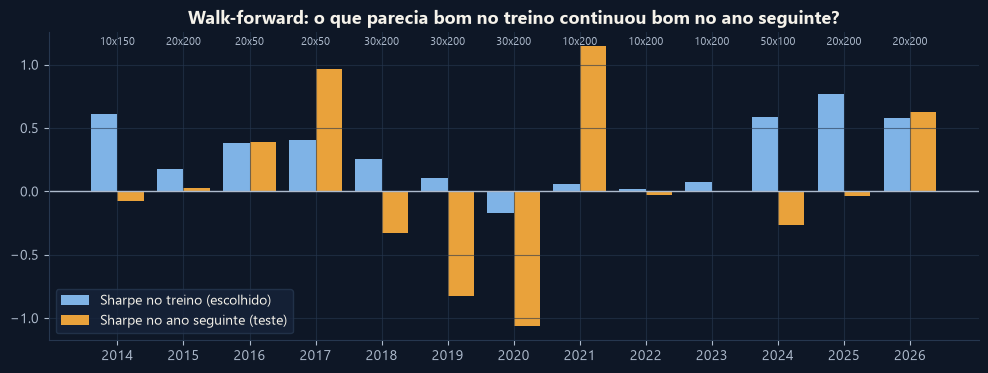

In [6]:
fig, ax = plt.subplots(figsize=(12, 4))
x = np.arange(len(wf))
ax.bar(x - 0.2, wf["sharpe_treino"], 0.4, color=CORES["secundaria"], label="Sharpe no treino (escolhido)")
ax.bar(x + 0.2, wf["sharpe_teste"], 0.4, color=CORES["primaria"], label="Sharpe no ano seguinte (teste)")
for i, e in enumerate(wf["escolha"]):
    ax.text(i, ax.get_ylim()[1] * 0.92, e, ha="center", fontsize=8, color=CORES["texto_suave"])
ax.axhline(0, color=CORES["texto_suave"], lw=1)
ax.set_xticks(x, wf.index)
ax.set_title("Walk-forward: o que parecia bom no treino continuou bom no ano seguinte?")
ax.legend(loc="lower left")
plt.show()

**Como ler:** se as barras âmbar (teste) acompanham as azuis (treino), a otimização captura algo real.
Se as azuis são sempre positivas e as âmbar oscilam em torno de zero, o "melhor parâmetro" de cada janela
era só o que **teve mais sorte** naquela janela. Repare também se a combinação escolhida muda muito de
um ano para o outro: parâmetro que pula de 5×50 para 50×200 é sinal de que não existe um ótimo estável.

## 5. Machine learning: o que é meta-labeling
A ideia mais comum, e mais perigosa, é pedir para um modelo **prever o preço** ("vai subir ou cair amanhã?").
Em forex isso é quase ruído puro, e o modelo acaba decorando o passado.

Aqui usamos uma técnica mais modesta e mais sólida, o **meta-labeling** (popularizada por Marcos López de Prado):

1. A **regra base** (cruzamento 20×50) continua decidindo **a direção** e **quando** entrar.
2. O modelo de ML só responde a uma pergunta de sim/não: **"este cruzamento específico vai dar lucro?"**
3. Se a probabilidade prevista for ≥ `PROB_MINIMA`, a operação é feita. Se não, ficamos **fora** até o próximo cruzamento.

Ou seja, o ML vira um **filtro**: ele não inventa operações, só pode pular as que parecem ruins.
Como trend following perde em mercado lateral, a esperança é que o modelo aprenda a reconhecer
"mercado lateral" pelas features e pule os *whipsaws*.

### Rótulo (o que o modelo tenta prever)
Para cada operação da regra base: `1` se o resultado **líquido de custos** foi positivo, `0` se não.

### Os dois modelos
| Modelo | Por que usar |
|---|---|
| **Regressão logística** | simples, linear, difícil de sofrer overfitting, dá para ler os coeficientes |
| **Random forest** (rasa: profundidade 3) | capta relações não lineares (ex.: "ADX alto **e** volatilidade baixa"), mas limitada para não decorar |

Os dois são leves: rodam em segundos no PC (nada de deep learning).

## 6. Features: as "pistas" que o modelo recebe
Todas são calculadas na **barra do sinal**, que já está fechada no momento da decisão (sem look-ahead).
As que têm direção são multiplicadas pela direção da operação (+1 compra, −1 venda), para que
"a favor da operação" seja sempre um número positivo, seja compra ou venda.

| Feature | O que mede | Intuição |
|---|---|---|
| `adx` | força da tendência (ADX 14) | ADX baixo = mercado lateral, ruim para cruzamento |
| `atr_pct` | volatilidade (ATR 14 ÷ preço) | mercado muito parado mal paga os custos |
| `regime_vol` | ATR 14 ÷ ATR 100 | a volatilidade está acelerando ou secando? |
| `incl_lenta` | inclinação da SMA 50 em 10 barras, em ATRs, a favor | tendência de fundo já apontando para o nosso lado? |
| `momento_20` | retorno das últimas 20 barras, em ATRs, a favor | o preço já andou a favor antes do cruzamento? |
| `dist_sma200` | distância do preço à SMA 200, em ATRs, a favor | a operação está alinhada com a tendência longa? |
| `cruzamentos_50` | nº de cruzamentos nas últimas 50 barras | muitos cruzamentos recentes = *whipsaw* |
| `direcao` | +1 compra, −1 venda | o par teve viés de alta ou de baixa? |

In [7]:
alta, baixa, fech = df["maxima"], df["minima"], df["fechamento"]
tr = pd.concat([alta - baixa, (alta - fech.shift()).abs(), (baixa - fech.shift()).abs()], axis=1).max(axis=1)
atr14 = tr.ewm(alpha=1 / 14, adjust=False).mean()
atr100 = tr.rolling(100).mean()

sobe, desce = alta.diff(), -baixa.diff()
dm_mais = pd.Series(np.where((sobe > desce) & (sobe > 0), sobe, 0.0), index=df.index)
dm_menos = pd.Series(np.where((desce > sobe) & (desce > 0), desce, 0.0), index=df.index)
di_mais = 100 * dm_mais.ewm(alpha=1 / 14, adjust=False).mean() / atr14
di_menos = 100 * dm_menos.ewm(alpha=1 / 14, adjust=False).mean() / atr14
adx = (100 * (di_mais - di_menos).abs() / (di_mais + di_menos)).ewm(alpha=1 / 14, adjust=False).mean()

sma_lenta = fech.rolling(MEDIA_LENTA).mean()
sma200 = fech.rolling(200).mean()
sinal_base = pos_base.shift(-1)  # sinal da barra fechada (a posição é ele deslocado)
cruzou = (sinal_base != sinal_base.shift(1)).astype(int)

feat_barra = pd.DataFrame(
    {
        "adx": adx,
        "atr_pct": atr14 / fech * 100,
        "regime_vol": atr14 / atr100,
        "incl_lenta": (sma_lenta - sma_lenta.shift(10)) / atr14,
        "momento_20": (fech - fech.shift(20)) / atr14,
        "dist_sma200": (fech - sma200) / atr14,
        "cruzamentos_50": cruzou.rolling(50).sum(),
    }
)
DIRECIONAIS = ["incl_lenta", "momento_20", "dist_sma200"]
FEATURES = list(feat_barra.columns) + ["direcao"]

# Uma linha por operação da regra base, com as features da barra do sinal (a barra anterior à entrada)
barra_sinal = df.index[df.index.get_indexer(trades_base["entrada"]) - 1]
ds = trades_base.copy()
ds[feat_barra.columns] = feat_barra.loc[barra_sinal].to_numpy()
ds[DIRECIONAIS] = ds[DIRECIONAIS].mul(ds["direcao"], axis=0)
ds["alvo"] = (ds["resultado"] > 0).astype(int)
ds = ds.dropna(subset=FEATURES).reset_index(drop=True)

print(f"{len(ds)} operações com features completas | taxa de acerto da regra base: {ds['alvo'].mean():.1%}")
ds.groupby("alvo")[FEATURES].mean().T.rename(columns={0: "média nas perdedoras", 1: "média nas vencedoras"}).round(3)

584 operações com features completas | taxa de acerto da regra base: 38.0%


alvo,média nas perdedoras,média nas vencedoras
adx,21.5160,22.8560
atr_pct,0.2890,0.2960
regime_vol,0.9860,1.0230
incl_lenta,-0.1580,-0.0920
momento_20,2.8850,3.0910
dist_sma200,0.1470,0.8760
cruzamentos_50,1.9030,1.9050
direcao,0.0110,-0.0180


**Primeira olhada:** a tabela compara a média de cada feature nas operações vencedoras e perdedoras.
Se as colunas forem quase iguais, as features **não separam** bons de maus cruzamentos e nenhum modelo vai
fazer milagre. Diferenças claras (ex.: ADX maior nas vencedoras) são o que o modelo pode aproveitar.

> Atenção: esta tabela usa **todas** as operações, inclusive as do futuro. Ela serve só para entender os dados,
> **nunca** para escolher features. O teste honesto vem a seguir.

## 7. Treino walk-forward dos modelos
O mesmo princípio da seção 4, agora para o ML:

- Para testar o ano **A**, o modelo é treinado com as operações que **encerraram** antes de 1º de janeiro de **A**.
  Uma operação que abriu em dezembro e fechou em fevereiro **não entra** no treino de fevereiro: em janeiro
  ainda não sabíamos o resultado dela (isso se chama *purging* e evita um vazamento sutil de informação).
- A janela de treino é **expansiva** (desde 2010): com só ~35 operações por ano, precisamos de toda a história disponível.
- O modelo prevê a probabilidade de acerto das operações que **abrem** no ano A. A operação é aceita se a probabilidade for ≥ `PROB_MINIMA`.
- Repetimos para todos os anos de 2014 em diante.

In [8]:
def novo_modelo(nome):
    if nome == "Logística":
        return make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=1000))
    return RandomForestClassifier(
        n_estimators=300, max_depth=3, min_samples_leaf=15, random_state=SEED, n_jobs=2
    )


MODELOS = ["Logística", "Random forest"]
for nome in MODELOS:
    ds[f"prob_{nome}"] = np.nan

for ano in anos_teste:
    ini, fim = pd.Timestamp(ano, 1, 1), pd.Timestamp(ano + 1, 1, 1)
    treino = ds["saida"] < ini  # só operações já encerradas (purging)
    teste = (ds["entrada"] >= ini) & (ds["entrada"] < fim)
    if treino.sum() < MIN_TRADES_ML or teste.sum() == 0:
        continue
    for nome in MODELOS:
        m = novo_modelo(nome).fit(ds.loc[treino, FEATURES], ds.loc[treino, "alvo"])
        ds.loc[teste, f"prob_{nome}"] = m.predict_proba(ds.loc[teste, FEATURES])[:, 1]

ds_oos = ds[ds["entrada"] >= pd.Timestamp(INICIO_OOS)].copy()
for nome in MODELOS:
    ds_oos[f"aceita_{nome}"] = ds_oos[f"prob_{nome}"] >= PROB_MINIMA
print(f"Operações fora da amostra: {len(ds_oos)} | com previsão: {ds_oos['prob_Logística'].notna().sum()}")

Operações fora da amostra: 461 | com previsão: 461


## 8. O filtro funcionou? Qualidade das previsões
Três maneiras de avaliar, da mais técnica à mais prática:

- **AUC**: probabilidade de o modelo dar nota maior a uma operação vencedora do que a uma perdedora sorteada.
  **0,50 = moeda**; acima de 0,55 já seria algo; acima de 0,60 é raro em mercado.
- **Acerto das aceitas × rejeitadas**: as operações que o modelo aceitou tiveram win rate maior que as que ele pulou?
- **Resultado médio**: o que importa no fim é a expectativa **em dinheiro** das aceitas ser maior que a das rejeitadas.

In [9]:
qual = {}
for nome in MODELOS:
    a = ds_oos[f"aceita_{nome}"]
    qual[nome] = {
        "AUC": roc_auc_score(ds_oos["alvo"], ds_oos[f"prob_{nome}"]),
        "% operações aceitas": a.mean() * 100,
        "Win rate aceitas %": ds_oos.loc[a, "alvo"].mean() * 100,
        "Win rate rejeitadas %": ds_oos.loc[~a, "alvo"].mean() * 100,
        "Expectativa aceitas %": ds_oos.loc[a, "resultado"].mean() * 100,
        "Expectativa rejeitadas %": ds_oos.loc[~a, "resultado"].mean() * 100,
    }
qualidade = pd.DataFrame(qual)
print(f"Win rate da regra base fora da amostra: {ds_oos['alvo'].mean():.1%}")
qualidade.round(3)

Win rate da regra base fora da amostra: 36.7%


,Logística,Random forest
AUC,0.5200,0.5080
% operações aceitas,11.4970,3.9050
Win rate aceitas %,52.8300,44.4440
Win rate rejeitadas %,34.5590,36.3430
Expectativa aceitas %,0.3020,0.0490
Expectativa rejeitadas %,-0.1080,-0.0650


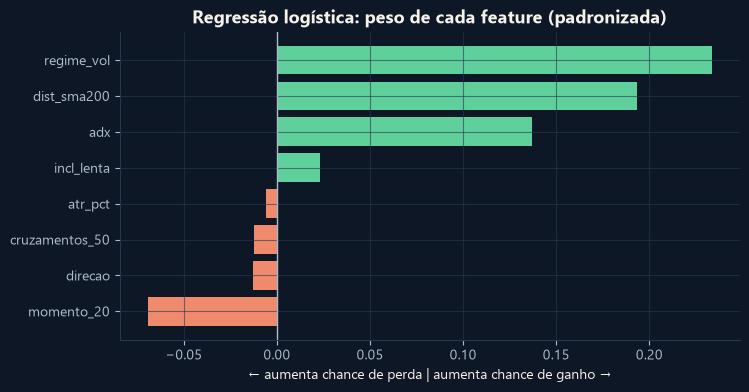

In [10]:
# O que o modelo aprendeu? Coeficientes da logística treinada com todas as operações até o último ano
ultimo = pd.Timestamp(list(anos_teste)[-1], 1, 1)
log_final = novo_modelo("Logística").fit(ds.loc[ds["saida"] < ultimo, FEATURES], ds.loc[ds["saida"] < ultimo, "alvo"])
coef = pd.Series(log_final[-1].coef_[0], index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(coef.index, coef.values, color=[CORES["positivo"] if v > 0 else CORES["negativo"] for v in coef])
ax.axvline(0, color=CORES["texto_suave"], lw=1)
ax.set_title("Regressão logística: peso de cada feature (padronizada)")
ax.set_xlabel("← aumenta chance de perda | aumenta chance de ganho →")
plt.show()

**Como ler:** barra verde = quanto maior a feature, maior a chance prevista de a operação dar lucro.
Barra vermelha = o contrário. Pesos perto de zero = a feature quase não ajuda.
Se os sinais fizerem sentido econômico (ex.: ADX e alinhamento com a SMA 200 positivos; muitos cruzamentos
recentes negativo), é um bom sinal. Pesos "esquisitos" com AUC perto de 0,50 indicam que o modelo está lendo ruído.

## 9. Filtro de ML × filtros aleatórios
Pular operações **muda** o resultado, mesmo sem inteligência nenhuma. Então a pergunta certa é:
*o filtro do modelo é melhor do que pular a **mesma quantidade** de operações ao acaso?*

Para cada modelo, sorteamos 300 filtros "macaco" que aceitam o mesmo nº de operações, escolhidas ao acaso
entre as mesmas operações fora da amostra. Como a regra base está sempre posicionada, pular uma operação
significa ficar fora nela, e o retorno total de qualquer filtro é simplesmente o produto dos resultados líquidos
das operações aceitas.

**Percentil** = % dos filtros aleatórios que ficaram abaixo do modelo. Acima de 95% começa a ser interessante.

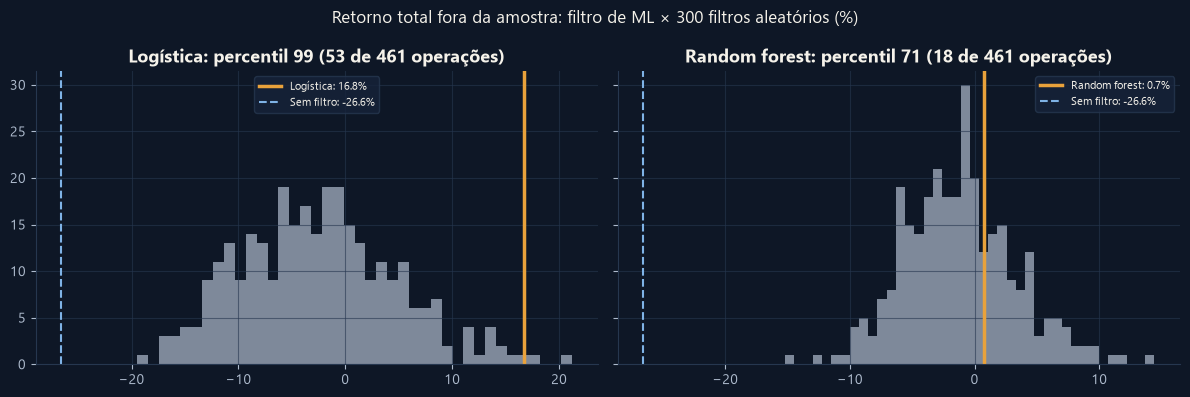

In [11]:
rng = np.random.default_rng(SEED)
res = ds_oos["resultado"].to_numpy()
total_base = (np.prod(1 + res) - 1) * 100
percentis = {}

fig, axes = plt.subplots(1, len(MODELOS), figsize=(12, 4), sharey=True)
for ax, nome in zip(axes, MODELOS):
    aceita = ds_oos[f"aceita_{nome}"].to_numpy()
    total_ml = (np.prod(1 + res[aceita]) - 1) * 100
    k = int(aceita.sum())
    aleat = np.array(
        [(np.prod(1 + res[rng.choice(len(res), size=k, replace=False)]) - 1) * 100 for _ in range(N_SIM)]
    )
    percentis[nome] = (aleat < total_ml).mean() * 100
    ax.hist(aleat, bins=40, color=CORES["texto_suave"], alpha=0.7)
    ax.axvline(total_ml, color=CORES["primaria"], lw=2.5, label=f"{nome}: {total_ml:.1f}%")
    ax.axvline(total_base, color=CORES["secundaria"], lw=1.5, ls="--", label=f"Sem filtro: {total_base:.1f}%")
    ax.set_title(f"{nome}: percentil {percentis[nome]:.0f} ({k} de {len(res)} operações)")
    ax.legend(fontsize=8)
plt.suptitle("Retorno total fora da amostra: filtro de ML × 300 filtros aleatórios (%)")
plt.tight_layout()
plt.show()

### 9b. Sensibilidade ao limiar de probabilidade
`PROB_MINIMA = 0,50` foi definido **antes** de ver os resultados, mas um bom filtro não pode depender de um
número mágico (o mesmo raciocínio do mapa de calor do 001). Recalculamos o filtro com vários limiares.
**Isto não serve para escolher o melhor limiar** (seria otimizar olhando o teste), só para ver se a vantagem
aparece numa faixa ampla ou só num ponto.

In [12]:
rng_s = np.random.default_rng(SEED)
linhas_s = []
for lim in [0.35, 0.40, 0.42, 0.45, 0.48, 0.50, 0.55]:
    for nome in MODELOS:
        aceita = (ds_oos[f"prob_{nome}"] >= lim).to_numpy()
        k = int(aceita.sum())
        if k == 0:
            continue
        total = (np.prod(1 + res[aceita]) - 1) * 100
        aleat = np.array([(np.prod(1 + res[rng_s.choice(len(res), size=k, replace=False)]) - 1) * 100 for _ in range(N_SIM)])
        linhas_s.append({"limiar": lim, "modelo": nome, "operações aceitas": k,
                         "retorno total %": total, "percentil vs aleatório": (aleat < total).mean() * 100})
sens = pd.DataFrame(linhas_s).pivot(index="limiar", columns="modelo")
sens.round(1)

operações aceitas               retorno total %                \
modelo         Logística Random forest       Logística Random forest   
limiar                                                                 
0.3500               309           346         -6.4000      -27.2000   
0.4000               187           170          0.3000       -5.8000   
0.4200               147           116          4.0000        1.4000   
0.4500                98            75          8.7000       13.7000   
0.4800                66            40         14.7000       13.7000   
0.5000                53            18         16.8000        0.7000   
0.5500                28             3          1.7000       -1.1000   

       percentil vs aleatório                
modelo              Logística Random forest  
limiar                                       
0.3500                87.7000       22.0000  
0.4000                84.7000       63.3000  
0.4200                87.7000       83.0000  
0.4500                91.0000       95.3000  
0.4800                98.7000       97.7000  
0.5000                99.7000       67.3000  
0.5500                72.3000       32.0000

## 10. Comparação final: fora da amostra (2014 → hoje)
Todas as versões medidas no **mesmo período** fora da amostra, com **os mesmos custos**:

| Versão | O que é |
|---|---|
| Buy & hold | ficar comprado o tempo todo |
| 20×50 fixo | a regra do 001, sem nada a mais |
| Walk-forward | médias reescolhidas todo ano (seção 4) |
| 20×50 + ML logística / random forest | regra base, pulando as operações que o modelo rejeitou (seções 7–9) |

As versões com filtro são montadas zerando a posição nas operações rejeitadas e recalculando tudo pelo
mesmo motor `retornos()`.

In [13]:
# id da operação de cada barra na regra base, para zerar as operações rejeitadas
grupo_base = (pos_base != pos_base.shift(1)).cumsum()
id_por_entrada = pd.Series(grupo_base.loc[trades_base["entrada"]].to_numpy(), index=trades_base["entrada"])


def posicao_filtrada(entradas_aceitas):
    aceitos = set(id_por_entrada.loc[list(entradas_aceitas)])
    return pos_base.where(grupo_base.isin(aceitos), 0.0)


versoes_pos = {
    "20x50 fixo": posicao_filtrada(ds_oos["entrada"]),
    "Walk-forward": pos_wf,
}
for nome in MODELOS:
    versoes_pos[f"20x50 + ML {nome.lower()}"] = posicao_filtrada(ds_oos.loc[ds_oos[f"aceita_{nome}"], "entrada"])

final, curvas = {"Buy & hold": metricas(ret_mercado[oos])}, {"Buy & hold": curva(ret_mercado[oos])}
for nome, p in versoes_pos.items():
    r = retornos(p)[oos]
    final[nome] = metricas(r, lista_trades(p[oos], r))
    curvas[nome] = curva(r)
final = pd.DataFrame(final)
final.round(2)

,Buy & hold,20x50 fixo,Walk-forward,20x50 + ML logística,20x50 + ML random forest
Retorno total %,-18.6300,-26.5700,-1.5100,16.7500,0.7500
CAGR %,-1.6000,-2.3900,-0.1200,1.2200,0.0600
Nº trades,NaN,461.0000,228.0000,53.0000,18.0000
Win rate %,NaN,36.6600,35.0900,52.8300,44.4400
Payoff,NaN,1.4900,1.8800,1.8300,1.3800
Expectativa %/trade,NaN,-0.0600,0.0100,0.3000,0.0500
Fator de lucro,NaN,0.8600,1.0200,2.0500,1.1100
Máx. drawdown %,-31.5500,-34.5700,-22.7100,-5.7900,-6.4900
Sharpe,-0.1700,-0.2700,0.0200,0.4200,0.0500
Sortino,-0.2300,-0.3800,0.0300,0.6100,0.0600


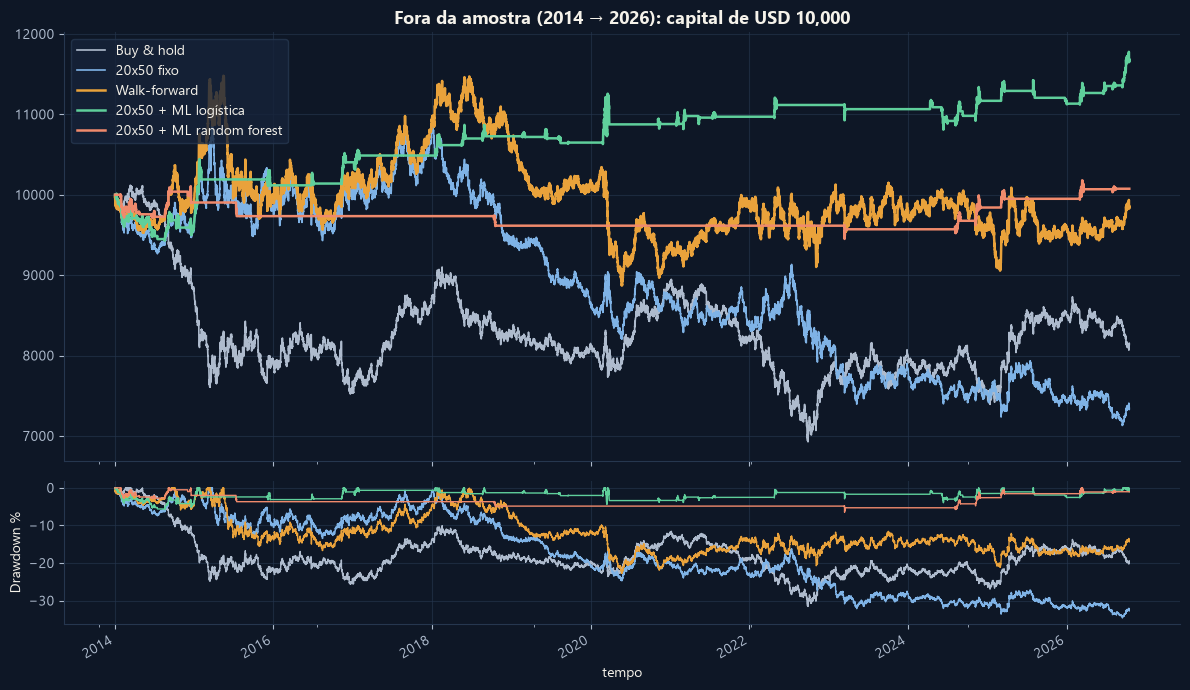

In [14]:
cores_v = [CORES["texto_suave"], CORES["secundaria"], CORES["primaria"], CORES["positivo"], CORES["negativo"]]
fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
for (nome, c), cor in zip(curvas.items(), cores_v):
    c.plot(ax=a1, color=cor, lw=1.8 if "ML" in nome or nome == "Walk-forward" else 1.2, label=nome)
    (drawdown(c) * 100).plot(ax=a2, color=cor, lw=1)
a1.set_title(f"Fora da amostra ({INICIO_OOS[:4]} → {df.index[-1]:%Y}): capital de USD {CAPITAL_INICIAL:,}")
a1.legend()
a2.set_ylabel("Drawdown %")
plt.tight_layout()
plt.show()

## 11. Salvar os resultados
Pasta `backtests/001.1_sma_wf_ml_EURUSD_H4/`:
- `parametros.json`: configuração exata;
- `metricas.csv`: comparação final fora da amostra;
- `walkforward.csv`: combinação escolhida em cada ano, com Sharpe de treino e de teste;
- `ml_operacoes_oos.csv`: cada operação fora da amostra com as features, a probabilidade de cada modelo e se foi aceita;
- `ml_qualidade.csv`: AUC e acerto das aceitas × rejeitadas.

In [15]:
PASTA_BACKTEST = RAIZ / "backtests" / f"{BACKTEST_ID}_sma_wf_ml_{SIMBOLO}_{TIMEFRAME}"
PASTA_BACKTEST.mkdir(parents=True, exist_ok=True)

parametros = {
    "id": BACKTEST_ID, "base": "001", "simbolo": SIMBOLO, "timeframe": TIMEFRAME,
    "media_rapida": MEDIA_RAPIDA, "media_lenta": MEDIA_LENTA,
    "slippage_pontos": SLIPPAGE_PONTOS, "comissao_pct": COMISSAO_PCT,
    "data_inicio": DATA_INICIO, "inicio_oos": INICIO_OOS, "dados_ate": f"{df.index[-1]:%Y-%m-%d}",
    "walkforward": {"anos_treino": ANOS_TREINO, "anos_teste": ANOS_TESTE, "grade_rapidas": GRADE_RAPIDAS,
                    "grade_lentas": GRADE_LENTAS, "min_trades_treino": MIN_TRADES_TREINO, "wfe": round(float(wfe), 3)},
    "ml": {"tecnica": "meta-labeling", "modelos": MODELOS, "features": FEATURES, "prob_minima": PROB_MINIMA,
           "min_trades_ml": MIN_TRADES_ML, "janela": "expansiva, retreino anual, purging por data de saída",
           "percentil_vs_filtro_aleatorio": {k: round(float(v), 1) for k, v in percentis.items()}},
    "seed": SEED,
}
(PASTA_BACKTEST / "parametros.json").write_text(json.dumps(parametros, indent=2, ensure_ascii=False), encoding="utf-8")
final.round(4).to_csv(PASTA_BACKTEST / "metricas.csv", encoding="utf-8")
wf.round(4).to_csv(PASTA_BACKTEST / "walkforward.csv", encoding="utf-8")
ds_oos.round(5).to_csv(PASTA_BACKTEST / "ml_operacoes_oos.csv", index=False, encoding="utf-8")
qualidade.round(4).to_csv(PASTA_BACKTEST / "ml_qualidade.csv", encoding="utf-8")
print(f"Resultados salvos em {PASTA_BACKTEST}")

Resultados salvos em C:\Dev\GitHub\LHS Capital\lhs-quant-lab\backtests\001.1_sma_wf_ml_EURUSD_H4


C:\Users\luizh\AppData\Local\Temp\ipykernel_11412\2232736183.py:19: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ds_oos.round(5).to_csv(PASTA_BACKTEST / "ml_operacoes_oos.csv", index=False, encoding="utf-8")


## 12. Conclusões e exercícios
### O que encontramos (rodada de 18/10/2026 — EURUSD H4, fora da amostra 2014 → out/2026)
| Versão | Retorno | Sharpe | Máx. DD | Trades | Fator de lucro |
|---|---:|---:|---:|---:|---:|
| Buy & hold | −18,6% | −0,17 | −31,6% | — | — |
| 20×50 fixo (regra do 001) | −26,6% | −0,27 | −34,6% | 461 | 0,86 |
| Walk-forward | −1,5% | 0,02 | −22,7% | 228 | 1,02 |
| 20×50 + ML logística | **+16,8%** | **0,42** | **−5,8%** | **53** | 2,05 |
| 20×50 + ML random forest | +0,8% | 0,05 | −6,5% | 18 | 1,11 |

**Walk-forward:** melhorou o resultado (de −26,6% para −1,5%) e bateu a 20×50 fixa em 9 de 13 anos, mas
**não criou vantagem**: Sharpe médio de 0,30 no treino caiu para 0,04 no teste (**WFE = 0,14**). O "melhor parâmetro"
de cada janela era em grande parte sorte. Uma pista útil: a otimização escolheu médias lentas de **150–200** em 10 de 13 anos.

**Machine learning (meta-labeling):**
- A **logística** foi o único resultado promissor: as operações aceitas tiveram win rate de **53%** contra 35% das rejeitadas,
  e o filtro ficou no **percentil 99** contra filtros aleatórios. A vantagem se manteve (percentil 85–99) em toda a faixa de limiares de 0,35 a 0,50.
- **Mas:** o AUC foi só **0,52** (quase moeda); o filtro aceitou só **53 operações em 13 anos** (20 delas em 2014) e
  a random forest, com as mesmas features, **não confirmou** (percentil 71). Com tão poucos trades, o resultado ainda pode ser sorte.
- A feature que mais separa vencedoras de perdedoras é `dist_sma200` (operar **a favor da SMA 200**), coerente com a preferência
  do walk-forward por médias de 200. A vantagem talvez venha de uma regra simples, sem ML nenhum.

**Veredito:** 🟡 **promissor, ainda não aprovado.** Nenhuma versão vai para conta demo ou real antes de passar no
próximo teste. Isso é o rigor funcionando: o resultado bonito (+16,8%, DD de −5,8%) chama atenção, mas tem poucos trades e só um dos dois modelos o confirma.

> Os números acima mudam conforme os dados forem atualizados. Ao rodar de novo, confira as tabelas.

### Próximo passo sugerido (Backtest 001.2 ou 002)
Testar a regra **sem ML**: *20×50 só a favor da SMA 200* (só compra acima, só vende abaixo). Se ela reproduzir a melhora,
a vantagem é simples e explicável. Depois disso, validar em **GBPUSD, USDJPY e D1** antes de qualquer conta demo.

### Exercícios
1. Mude `SIMBOLO` para `"GBPUSD"` e rode tudo. O filtro da logística continua no percentil > 95? (É o teste mais importante.)
2. Remova `dist_sma200` de `FEATURES`. O filtro ainda funciona sem ela?
3. Troque `ANOS_TREINO` para 3 e 6. O WFE melhora?
4. Coloque `SLIPPAGE_PONTOS = 10`. Quais versões sobrevivem a uma execução ruim?
5. Aumente `max_depth` da random forest para 8. O resultado fora da amostra melhora ou piora? (Dica: overfitting.)